# Stronghold Demobilization: Size, Partisanship, and the Counterfactual

Part 2 found that Democratic strongholds lost votes through turnout. This notebook sizes that, asks who the stay-homes were, and runs the counterfactual that matters: if 2020 voters who stayed home in 2024 had voted as they did in 2020, what changes?

The counterfactual needs the partisan lean of the stay-homes, which county returns cannot give. Two individual-level sources can:

- **CES 2024 cross-section** (60,000; 34,666 matched to a voter file with a recalled 2020 vote). Large, retains disengaged respondents, but 2020 vote is recalled.
- **CES 2020–2024 panel** (6,175). 2020 vote reported in 2020, but the retained panel is engaged and under-represents exactly the people who stay home.

Both have TargetSmart-validated 2024 turnout.

**Inputs:** `data/processed/county_decomposition.csv`, `data/raw/mit_election_lab/county_returns.csv`, `data/raw/ces/CCES24_Common_OUTPUT_vv_topost_final.csv`, `data/raw/ces_panel/ces_panel_wide.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

RAW_DIR = Path('../data/raw'); PROC_DIR = Path('../data/processed')
FIGURES_DIR = Path('../outputs/figures'); TABLES_DIR = Path('../outputs/tables')

def wmean(x, w):
    m = x.notna() & w.notna()
    return np.average(x[m], weights=w[m]) if m.any() else np.nan

SWING = ['PENNSYLVANIA', 'MICHIGAN', 'WISCONSIN', 'GEORGIA', 'ARIZONA', 'NEVADA', 'NORTH CAROLINA']
SWING_FIPS = {42: 'PENNSYLVANIA', 26: 'MICHIGAN', 55: 'WISCONSIN', 13: 'GEORGIA', 4: 'ARIZONA', 32: 'NEVADA', 37: 'NORTH CAROLINA'}

## 1. Size: Democratic vote change by county partisanship

In [2]:
c = pd.read_csv(PROC_DIR / 'county_decomposition.csv')
c['bin'] = pd.cut(c['dem_share_2020'], [0, .35, .45, .55, .65, 1.01],
                  labels=['<35% (R strongholds)', '35-45%', '45-55% (competitive)', '55-65% (lean D)', '65%+ (D strongholds)'])
rows = []
for b, g in c.groupby('bin'):
    rows.append({'county_2020_dem_share': b, 'counties': len(g), 'share_of_2020_votes': g['total_votes_2020'].sum() / c['total_votes_2020'].sum(),
                 'share_of_2020_dem_votes': g['dem_votes_2020'].sum() / c['dem_votes_2020'].sum(),
                 'delta_dem_M': g['delta_dem'].sum() / 1e6, 'turnout_component_M': g['turnout_component'].sum() / 1e6,
                 'share_component_M': g['share_component'].sum() / 1e6,
                 'turnout_change_pct': (g['total_votes_2024'].sum() / g['total_votes_2020'].sum() - 1) * 100,
                 'dem_share_change_pp': (g['dem_votes_2024'].sum() / g['total_votes_2024'].sum() - g['dem_votes_2020'].sum() / g['total_votes_2020'].sum()) * 100})
by_bin = pd.DataFrame(rows).set_index('county_2020_dem_share')
print(by_bin.round(3).to_string())
s = c[c['dem_share_2020'] >= .65]
print(f'\nD strongholds (65%+): {len(s)} counties, {s["total_votes_2020"].sum() / c["total_votes_2020"].sum():.1%} of 2020 votes, {s["dem_votes_2020"].sum() / c["dem_votes_2020"].sum():.1%} of 2020 Dem votes')
print(f'  Dem votes {s["dem_votes_2020"].sum() / 1e6:.2f}M -> {s["dem_votes_2024"].sum() / 1e6:.2f}M ({s["dem_votes_2024"].sum() / s["dem_votes_2020"].sum() - 1:+.1%})')
print(f'  non-Dem votes {(s["total_votes_2020"] - s["dem_votes_2020"]).sum() / 1e6:.2f}M -> {(s["total_votes_2024"] - s["dem_votes_2024"]).sum() / 1e6:.2f}M')
print(f'  share of national Dem vote loss: {s["delta_dem"].sum() / c["delta_dem"].sum():.0%}   share of national turnout component: {s["turnout_component"].sum() / c["turnout_component"].sum():.0%}')
print(f'  in 7 swing states: {s[s["state"].isin(SWING)]["delta_dem"].sum() / 1e6:+.2f}M   CA+NY+IL: {s[s["state"].isin(["CALIFORNIA", "NEW YORK", "ILLINOIS"])]["delta_dem"].sum() / 1e6:+.2f}M')
top = s.nsmallest(10, 'delta_dem')[['state', 'county_fips', 'dem_share_2020', 'dem_votes_2020', 'dem_votes_2024', 'delta_dem', 'turnout_component', 'share_component']]
print('\nLargest stronghold Dem vote losses:'); print(top.round(0).astype({'delta_dem': int, 'turnout_component': int, 'share_component': int}).to_string(index=False))

                       counties  share_of_2020_votes  share_of_2020_dem_votes  delta_dem_M  turnout_component_M  share_component_M  turnout_change_pct  dem_share_change_pp
county_2020_dem_share                                                                                                                                                      
<35% (R strongholds)       1903                0.187                    0.096       -0.157                0.167             -0.324               2.135               -1.069
35-45%                      539                0.156                    0.122       -0.288                0.108             -0.396               1.171               -1.618
45-55% (competitive)        322                0.226                    0.224       -1.198               -0.270             -0.929              -1.404               -2.677
55-65% (lean D)             197                0.219                    0.254       -1.678               -0.802             -0.876          

## 2. Who stayed home: partisanship of 2020 voters who did not vote in 2024

Validated non-voting in 2024 by 2020 vote, from both sources. `TS_g2024` is TargetSmart's 2024 general-election record (1–6 voted by method, 7 did not vote, missing = not matched).

In [3]:
# Cross-section
raw = pd.read_csv(RAW_DIR / 'ces' / 'CCES24_Common_OUTPUT_vv_topost_final.csv',
                  usecols=['caseid', 'inputstate', 'TS_g2024', 'TS_voterstatus', 'vvweight', 'vvweight_post', 'commonweight', 'presvote20post', 'CC24_410'], low_memory=False)
raw['matched'] = raw['TS_voterstatus'].notna() | raw['TS_g2024'].notna()
raw['stay'] = np.where(raw['TS_g2024'].notna() & (raw['TS_g2024'] != 7), 0.0, np.where(raw['matched'], 1.0, np.nan))
raw['v20'] = raw['presvote20post'].map({1: 'Biden', 2: 'Trump', 3: 'other', 4: 'other', 5: 'other', 6: 'did not vote'})
raw['v24'] = np.select([raw['CC24_410'] == 1, raw['CC24_410'] == 2, raw['CC24_410'].between(3, 7)], ['Harris', 'Trump', 'third party'], None)
xs = raw[raw['matched'] & raw['v20'].isin(['Biden', 'Trump'])].copy()
xs['wt'] = xs['vvweight_post'].fillna(xs['vvweight']).fillna(xs['commonweight'])

# Panel
wp = pd.read_csv(RAW_DIR / 'ces_panel' / 'ces_panel_wide.csv', low_memory=False)
pn = wp[(wp['voted_validated_2020'] == 1) & wp['voted_validated_2024'].notna() & wp['presvote_post_party_2020'].isin(['D', 'R'])].copy()
pn['wt'] = pn['commonpostweight_24'].fillna(pn['commonweight_24'])
pn['stay'] = (pn['voted_validated_2024'] == 0).astype(float)
pn['v20'] = pn['presvote_post_party_2020'].map({'D': 'Biden', 'R': 'Trump'})
pn['v24'] = pn['presvote_post_party_2024'].map({'D': 'Harris', 'R': 'Trump', 'other': 'third party'})

rows = []
for name, df in [('cross-section (recalled 2020 vote)', xs), ('panel (2020 vote reported in 2020)', pn)]:
    sh = df[df['stay'] == 1]
    rows.append({'source': name, 'N_matched': len(df), 'N_stay_home': len(sh),
                 'stay_rate_all': wmean(df['stay'], df['wt']),
                 'stay_rate_Biden_voters': wmean(df.loc[df['v20'] == 'Biden', 'stay'], df.loc[df['v20'] == 'Biden', 'wt']),
                 'stay_rate_Trump_voters': wmean(df.loc[df['v20'] == 'Trump', 'stay'], df.loc[df['v20'] == 'Trump', 'wt']),
                 'stay_homes_pct_Biden': wmean((sh['v20'] == 'Biden').astype(float), sh['wt']),
                 'recalled_D_over_R': (df['v20'] == 'Biden').sum() / (df['v20'] == 'Trump').sum()})
who = pd.DataFrame(rows).set_index('source')
print(who.round(3).to_string())
print('\nActual 2020 Biden/Trump vote ratio: 1.09. The cross-section over-recalls Biden votes; the panel does not (contemporaneous).')
print('The panel retained engaged respondents: its overall stay-home rate is a third of the cross-section\'s.')

                                    N_matched  N_stay_home  stay_rate_all  stay_rate_Biden_voters  stay_rate_Trump_voters  stay_homes_pct_Biden  recalled_D_over_R
source                                                                                                                                                            
cross-section (recalled 2020 vote)      34666         1961          0.075                   0.089                   0.059                 0.642              1.421
panel (2020 vote reported in 2020)       3982          136          0.025                   0.019                   0.031                 0.405              1.278

Actual 2020 Biden/Trump vote ratio: 1.09. The cross-section over-recalls Biden votes; the panel does not (contemporaneous).
The panel retained engaged respondents: its overall stay-home rate is a third of the cross-section's.


## 3. Stay home or flip? Outcomes for 2020 voters who left their 2020 column

In [4]:
def outcomes(df, p, flip):
    b = df[df['v20'] == p].copy()
    b['o'] = np.where(b['stay'] == 1, 'stayed home', b['v24'].fillna('voted, no answer'))
    k = b[b['o'] != 'voted, no answer']
    same = 'Harris' if p == 'Biden' else 'Trump'
    left = k[k['o'] != same]
    return {'N_known': len(k), **{o: wmean((k['o'] == o).astype(float), k['wt']) for o in [same, flip, 'third party', 'stayed home']},
            'N_left': len(left),
            'of_leavers_stayed_home': wmean((left['o'] == 'stayed home').astype(float), left['wt']),
            'of_leavers_flipped': wmean((left['o'] == flip).astype(float), left['wt']),
            'of_leavers_third': wmean((left['o'] == 'third party').astype(float), left['wt'])}
rows = []
for name, df in [('cross-section', xs), ('panel', pn)]:
    for p, flip in [('Biden', 'Trump'), ('Trump', 'Harris')]:
        rows.append({'source': name, '2020 vote': p, **outcomes(df, p, flip)})
flipstay = pd.DataFrame(rows).set_index(['source', '2020 vote'])
print(flipstay.round(3).T.to_string())

source                 cross-section                panel          
2020 vote                      Biden      Trump     Biden     Trump
N_known                    18182.000  13517.000  1391.000  1345.000
Harris                         0.844      0.015     0.957     0.029
Trump                          0.047      0.918     0.014     0.920
third party                    0.009      0.004     0.006     0.014
stayed home                    0.100      0.063     0.024     0.037
N_left                      1709.000   1277.000   112.000   115.000
of_leavers_stayed_home         0.645      0.761     0.553     0.457
of_leavers_flipped             0.300      0.188     0.314     0.363
of_leavers_third               0.056      0.051     0.133     0.180


## 4. Counterfactual: 2020 voters who stayed home in 2024 vote as they did in 2020

Stay-home rates by 2020 vote from the cross-section, by state, applied to actual 2020 state vote totals. Net margin effect = (Biden 2020 votes × Biden stay rate) − (Trump 2020 votes × Trump stay rate). Compared to the actual 2024 margin.

This is the correct counterfactual for "what if the stay-homes had voted." It is not the one in Part 2's county analysis, which assumed stay-homes voted like the 2024 electorate and therefore found no effect.

In [5]:
ret = pd.read_csv(RAW_DIR / 'mit_election_lab' / 'county_returns.csv')
s20 = ret[ret['year'] == 2020].groupby('state')[['dem_votes', 'rep_votes']].sum()
s24 = ret[ret['year'] == 2024].groupby('state')[['dem_votes', 'rep_votes']].sum()
rD = wmean(xs.loc[xs['v20'] == 'Biden', 'stay'], xs.loc[xs['v20'] == 'Biden', 'wt'])
rR = wmean(xs.loc[xs['v20'] == 'Trump', 'stay'], xs.loc[xs['v20'] == 'Trump', 'wt'])
rows = []
for f, st in SWING_FIPS.items():
    x = xs[xs['inputstate'] == f]; d = x[x['v20'] == 'Biden']; r = x[x['v20'] == 'Trump']
    sd, sr = wmean(d['stay'], d['wt']), wmean(r['stay'], r['wt'])
    Dsh, Rsh = s20.loc[st, 'dem_votes'] * sd, s20.loc[st, 'rep_votes'] * sr
    marg = s24.loc[st, 'dem_votes'] - s24.loc[st, 'rep_votes']
    rows.append({'state': st, 'margin_2024': marg, 'n_Biden_resp': len(d), 'n_Trump_resp': len(r), 'stay_rate_Biden': sd, 'stay_rate_Trump': sr,
                 'Biden_stay_homes': Dsh, 'Trump_stay_homes': Rsh, 'net_to_Dem': Dsh - Rsh, 'cf_margin': marg + Dsh - Rsh, 'flips': marg + Dsh - Rsh > 0})
Dn, Rn = s20['dem_votes'].sum() * rD, s20['rep_votes'].sum() * rR
natm = s24['dem_votes'].sum() - s24['rep_votes'].sum()
rows.append({'state': 'NATIONAL', 'margin_2024': natm, 'n_Biden_resp': int((xs['v20'] == 'Biden').sum()), 'n_Trump_resp': int((xs['v20'] == 'Trump').sum()),
             'stay_rate_Biden': rD, 'stay_rate_Trump': rR, 'Biden_stay_homes': Dn, 'Trump_stay_homes': Rn, 'net_to_Dem': Dn - Rn, 'cf_margin': natm + Dn - Rn, 'flips': natm + Dn - Rn > 0})
cf = pd.DataFrame(rows).set_index('state')
pd.set_option('display.float_format', lambda v: f'{v:,.3f}' if abs(v) < 1 else f'{v:,.0f}')
print(cf.to_string())
pd.reset_option('display.float_format')

                margin_2024  n_Biden_resp  n_Trump_resp  stay_rate_Biden  stay_rate_Trump  Biden_stay_homes  Trump_stay_homes  net_to_Dem  cf_margin  flips
state                                                                                                                                                      
PENNSYLVANIA        -120266          1043           855            0.032            0.035           111,228           117,853      -6,625   -126,891  False
MICHIGAN             -80103           736           468            0.114            0.037           321,033            99,163     221,869    141,766   True
WISCONSIN            -29397           457           296            0.035            0.036            56,715            57,963      -1,248    -30,645  False
GEORGIA             -115100           656           471            0.097            0.057           241,001           139,988     101,013    -14,087  False
ARIZONA             -187382           472           433         

In [6]:
# Recall-bias sensitivity: scale the Biden stay-home count by actual/recalled Biden share of the 2020 electorate
adj = 1.09 / who.loc['cross-section (recalled 2020 vote)', 'recalled_D_over_R']
print(f'Recall adjustment factor on Biden stay-homes: {adj:.2f}')
cf['net_to_Dem_recall_adj'] = cf['Biden_stay_homes'] * adj - cf['Trump_stay_homes']
cf['cf_margin_recall_adj'] = cf['margin_2024'] + cf['net_to_Dem_recall_adj']
cf['flips_recall_adj'] = cf['cf_margin_recall_adj'] > 0
print(cf[['margin_2024', 'net_to_Dem', 'flips', 'net_to_Dem_recall_adj', 'flips_recall_adj']].round(0).to_string())
print('\nThe adjustment assumes recall bias is uniform across voters and non-voters. If 2024 non-voters over-recall Biden votes')
print('more than voters do, the true Democratic share of stay-homes is lower still; the direction of the bias is known, its size is not.')

Recall adjustment factor on Biden stay-homes: 0.77
                margin_2024  net_to_Dem  flips  net_to_Dem_recall_adj  flips_recall_adj
state                                                                                  
PENNSYLVANIA        -120266     -6625.0  False               -32543.0             False
MICHIGAN             -80103    221869.0   True               147064.0              True
WISCONSIN            -29397     -1248.0  False               -14464.0             False
GEORGIA             -115100    101013.0  False                44856.0             False
ARIZONA             -187382     34431.0  False                11492.0             False
NEVADA               -46008    -20720.0  False               -26418.0             False
NORTH CAROLINA      -183048    135322.0  False                84605.0             False
NATIONAL           -2289953   2802753.0   True              1124170.0             False

The adjustment assumes recall bias is uniform across voters and non-

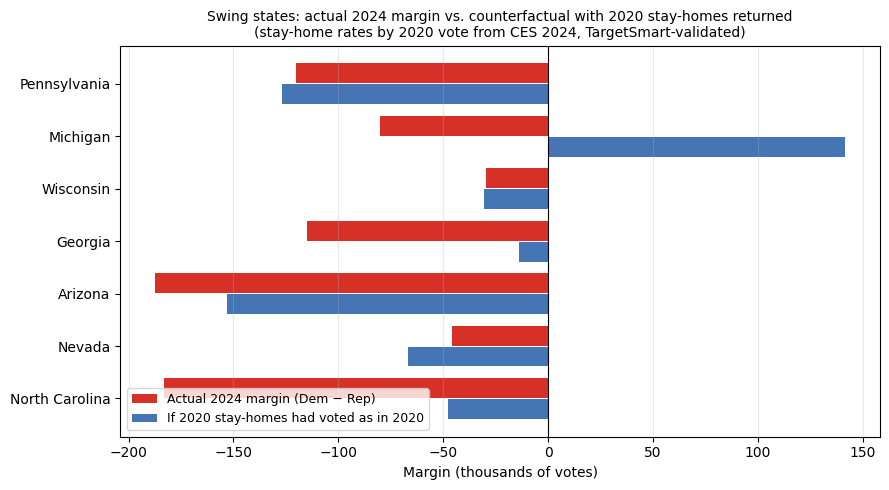

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
st = cf.drop(index='NATIONAL')
y = np.arange(len(st))[::-1]
ax.barh(y + 0.2, st['margin_2024'] / 1e3, height=0.38, color='#d73027', label='Actual 2024 margin (Dem − Rep)')
ax.barh(y - 0.2, st['cf_margin'] / 1e3, height=0.38, color='#4575b4', label='If 2020 stay-homes had voted as in 2020')
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels([s.title() for s in st.index])
ax.set_xlabel('Margin (thousands of votes)')
ax.set_title('Swing states: actual 2024 margin vs. counterfactual with 2020 stay-homes returned\n(stay-home rates by 2020 vote from CES 2024, TargetSmart-validated)', fontsize=10)
ax.legend(fontsize=9, loc='lower left'); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'stayhome_counterfactual.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Save

In [8]:
by_bin.to_csv(TABLES_DIR / 'stayhome_by_county_bin.csv'); who.to_csv(TABLES_DIR / 'stayhome_partisanship.csv')
flipstay.to_csv(TABLES_DIR / 'stayhome_vs_flip.csv'); cf.to_csv(TABLES_DIR / 'stayhome_counterfactual.csv')
print('Saved: outputs/tables/stayhome_by_county_bin.csv, stayhome_partisanship.csv, stayhome_vs_flip.csv, stayhome_counterfactual.csv; outputs/figures/stayhome_counterfactual.png')

Saved: outputs/tables/stayhome_by_county_bin.csv, stayhome_partisanship.csv, stayhome_vs_flip.csv, stayhome_counterfactual.csv; outputs/figures/stayhome_counterfactual.png


## Limitations

- **State cells are small.** 300–1,000 respondents per swing state per party; Michigan's 11.4% Biden stay-home rate rests on 736 recalled-Biden voters. National rates are solid; single-state figures are ±several points.
- **Recall bias runs in one direction.** The cross-section over-recalls Biden votes (ratio 1.42 vs actual 1.09). If 2024 non-voters misremember 2020 more than voters do, the Democratic share of stay-homes is overstated. The recall-adjusted column assumes uniform bias.
- **The panel disagrees, and is the wrong instrument.** It shows Trump 2020 voters staying home slightly more (3.7% vs 2.4%). Its overall stay-home rate is 2.5% against 7–9% in the cross-section; the panel retained the engaged and lost the people this question is about.
- **Everything else is held fixed.** Roughly 11M 2020 voters dropped out and 8M new voters entered. Returning the drop-outs does not remove the new voters, who leaned Republican.
- **Two counterfactuals, two answers.** The county-level version (Part 2 framing: restore turnout at 2024 shares) finds nothing because it assumes stay-homes mirror voters. This version finds a state because it uses the stay-homes' own partisanship. The second is the right one for the question asked; both are reported so the difference is visible.